# Stage 1 — Dataset Exploration
**Capstone: Multimodal Ocular Disease Prediction (Myopia + other conditions)**

This notebook is the first stage of the tabular/clinical ML pipeline:

`full_df.csv` → **Data Exploration** → Data Cleaning → Feature Identification → Encoding → Normalization → Feature Selection → Patient-level Split → Classification → Evaluation

This notebook only covers **Data Exploration**. Nothing is cleaned, encoded, or modeled yet — the goal is to understand exactly what we're working with before we touch it.


## 1. Setup and load the dataset

This project folder is organized as:
```
Capstone Datasets/
├── Data/            <- full_df.csv and other data files live here
├── Code/
│   └── notebooks/   <- this notebook lives here
└── Documentation/
```

Run this in Google Colab. The load cell below checks a few likely locations for `full_df.csv` (including the `Data/` folder if you've mounted/uploaded the whole project), and falls back to an upload widget if it can't find it anywhere.

In [1]:
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

IN_COLAB = "google.colab" in sys.modules

CANDIDATE_PATHS = [
    "../../Data/full_df.csv",  # running locally from Code/notebooks/ in the project folder
    "Data/full_df.csv",        # running from the project root
    "full_df.csv",             # uploaded directly / same folder
]

DATA_PATH = next((p for p in CANDIDATE_PATHS if os.path.exists(p)), None)

if DATA_PATH is None and IN_COLAB:
    from google.colab import files
    print("Could not find full_df.csv automatically — please upload it.")
    uploaded = files.upload()
    DATA_PATH = "full_df.csv"

if DATA_PATH is None:
    raise FileNotFoundError(
        "full_df.csv not found. Checked: " + ", ".join(CANDIDATE_PATHS)
    )

df = pd.read_csv(DATA_PATH)
print("Loaded:", DATA_PATH)
print("Shape (rows, columns):", df.shape)


Loaded: ../../Data/full_df.csv
Shape (rows, columns): (6392, 19)


**Expected output:** `Shape (rows, columns): (6392, 19)`

If your shape is different, stop here and tell me — it means your copy of the CSV doesn't match the one we inspected.

## 2. Look at the columns and a few sample rows

In [2]:
print("Columns:")
for c in df.columns:
    print(" -", c)


Columns:
 - ID
 - Patient Age
 - Patient Sex
 - Left-Fundus
 - Right-Fundus
 - Left-Diagnostic Keywords
 - Right-Diagnostic Keywords
 - N
 - D
 - G
 - C
 - A
 - H
 - M
 - O
 - filepath
 - labels
 - target
 - filename


In [3]:
df.head(5)

,ID,Patient Age,Patient Sex,Left-Fundus,Right-Fundus,Left-Diagnostic Keywords,Right-Diagnostic Keywords,N,D,G,C,A,H,M,O,filepath,labels,target,filename
0,0,69,Female,0_left.jpg,0_right.jpg,cataract,normal fundus,0,0,0,1,0,0,0,0,../input/ocular-disease-recognition-odir5k/ODI...,['N'],"[1, 0, 0, 0, 0, 0, 0, 0]",0_right.jpg
1,1,57,Male,1_left.jpg,1_right.jpg,normal fundus,normal fundus,1,0,0,0,0,0,0,0,../input/ocular-disease-recognition-odir5k/ODI...,['N'],"[1, 0, 0, 0, 0, 0, 0, 0]",1_right.jpg
2,2,42,Male,2_left.jpg,2_right.jpg,laser spot，moderate non proliferative retinopathy,moderate non proliferative retinopathy,0,1,0,0,0,0,0,1,../input/ocular-disease-recognition-odir5k/ODI...,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]",2_right.jpg
3,4,53,Male,4_left.jpg,4_right.jpg,macular epiretinal membrane,mild nonproliferative retinopathy,0,1,0,0,0,0,0,1,../input/ocular-disease-recognition-odir5k/ODI...,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]",4_right.jpg
4,5,50,Female,5_left.jpg,5_right.jpg,moderate non proliferative retinopathy,moderate non proliferative retinopathy,0,1,0,0,0,0,0,0,../input/ocular-disease-recognition-odir5k/ODI...,['D'],"[0, 1, 0, 0, 0, 0, 0, 0]",5_right.jpg


**What to check:** the disease columns `N, D, G, C, A, H, M, O` are 0/1 flags (one column per condition), not a single label column. `labels` and `target` are text/derived versions of the same information — these are diagnosis-derived columns, **not features** we can train on (using them would leak the answer into the model). We'll deal with that formally in the cleaning stage; for now just confirm you can see this structure.

## 3. Data types and missing values

In [4]:
info_df = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().sum() / len(df) * 100).round(2),
})
info_df

,dtype,n_missing,pct_missing
ID,int64,0,0.0
Patient Age,int64,0,0.0
Patient Sex,str,0,0.0
Left-Fundus,str,0,0.0
Right-Fundus,str,0,0.0
Left-Diagnostic Keywords,str,0,0.0
Right-Diagnostic Keywords,str,0,0.0
N,int64,0,0.0
D,int64,0,0.0
G,int64,0,0.0


**Expected output:** every column should show `n_missing = 0`. If any column shows missing values, note which one — we'll handle it in the cleaning stage.

## 4. Duplicate rows

In [5]:
n_dupes = df.duplicated().sum()
print("Fully duplicated rows:", n_dupes)

n_dupe_ids = df.duplicated(subset=["ID", "filename"]).sum()
print("Duplicate (ID, filename) pairs:", n_dupe_ids)


Fully duplicated rows: 0
Duplicate (ID, filename) pairs: 0


## 5. Patient-level structure (why we must NOT do a naive random split)

In [6]:
n_rows = len(df)
n_patients = df["ID"].nunique()
print("Total rows (images):", n_rows)
print("Unique patients (ID):", n_patients)

rows_per_patient = df.groupby("ID").size()
print()
print("Rows per patient — value counts:")
print(rows_per_patient.value_counts().sort_index())


Total rows (images): 6392
Unique patients (ID): 3358

Rows per patient — value counts:
1     324
2    3034
Name: count, dtype: int64


**Why this matters:** most patients contribute 2 rows (left eye + right eye), a smaller number contribute 1. If we split rows randomly into train/test, both eyes of the same patient can end up on different sides of the split. That leaks patient-specific information (age, underlying health, image style) into the "test" set and inflates accuracy artificially. Later, we will split by patient `ID`, not by row.

## 6. Class balance — and an important finding: this is a MULTI-LABEL dataset

In [7]:
disease_cols = ["N", "D", "G", "C", "A", "H", "M", "O"]

print("Positive count per condition (how many rows are flagged 1):")
print(df[disease_cols].sum().sort_values(ascending=False))


Positive count per condition (how many rows are flagged 1):
D    2123
N    2101
O    1588
C     402
G     397
A     319
M     306
H     203
dtype: int64


In [8]:
df["n_conditions"] = df[disease_cols].sum(axis=1)
print("Number of conditions flagged per row:")
print(df["n_conditions"].value_counts().sort_index())
print()
print("Rows with 0 conditions flagged (should be 0):", (df["n_conditions"] == 0).sum())
print("Rows with 2+ conditions flagged:", (df["n_conditions"] >= 2).sum(),
      f"({(df['n_conditions'] >= 2).mean()*100:.1f}% of rows)")


Number of conditions flagged per row:
n_conditions
1    5391
2     955
3      46
Name: count, dtype: int64

Rows with 0 conditions flagged (should be 0): 0
Rows with 2+ conditions flagged: 1001 (15.7% of rows)


**This is important and easy to miss.** The eight condition columns are not mutually exclusive — a meaningful fraction of rows have two or three conditions flagged at once (for example, Diabetes *and* Myopia on the same patient). This means:

- Experiment 1 (Myopia vs Non-Myopia) is straightforward: use the `M` column directly as a binary target, regardless of what else is flagged.
- Experiment 2 (multi-class: Normal/Diabetes/Glaucoma/.../Myopia/Other) is **not** a clean single-label problem as originally framed. We will need to explicitly decide — and document — how to handle the multi-condition rows (e.g. restrict the multi-class experiment to single-label rows only, and say so; or treat it as a genuine multi-label classification problem). We are not deciding this yet — just flagging it here with evidence, so it doesn't surprise us later.

## 7. Myopia in detail (Experiment 1 target)

In [9]:
myopia_rows = df[df["M"] == 1]
print("Rows with Myopia flagged:", len(myopia_rows))
print("Of those, Myopia is the ONLY condition flagged:", (myopia_rows["n_conditions"] == 1).sum())
print("Of those, Myopia co-occurs with another condition:", (myopia_rows["n_conditions"] > 1).sum())
print()
print("Class balance for Experiment 1 (Myopia vs Non-Myopia):")
print(df["M"].value_counts())
print((df["M"].value_counts(normalize=True) * 100).round(2).astype(str) + "%")


Rows with Myopia flagged: 306
Of those, Myopia is the ONLY condition flagged: 206
Of those, Myopia co-occurs with another condition: 100

Class balance for Experiment 1 (Myopia vs Non-Myopia):
M
0    6086
1     306
Name: count, dtype: int64
M
0    95.21%
1     4.79%
Name: proportion, dtype: str


**Expected output:** Myopia is a small minority class (roughly 5% of rows). This confirms Experiment 1 is an imbalanced binary classification problem — we'll need to handle that deliberately in the modeling stage (e.g. class weighting), not ignore it.

## 8. Demographics — Age and Sex

In [10]:
print(df["Patient Sex"].value_counts())
print()
print(df["Patient Age"].describe())


Patient Sex
Male      3424
Female    2968
Name: count, dtype: int64

count    6392.000000
mean       57.857947
std        11.727737
min         1.000000
25%        51.000000
50%        59.000000
75%        66.000000
max        91.000000
Name: Patient Age, dtype: float64


**Sanity check on age.** The minimum age looks suspiciously low for a dataset of this kind — worth checking whether it's a real value or a placeholder for unknown/missing age before we trust it in modeling.

In [11]:
suspicious_age = df[df["Patient Age"] < 5]
print("Rows with Patient Age < 5:", len(suspicious_age))
print(suspicious_age[["ID", "Patient Age", "Patient Sex"]].head(10))


Rows with Patient Age < 5: 28
        ID  Patient Age Patient Sex
1013  1242            1      Female
1218  1563            1      Female
1219  1564            1      Female
1220  1565            1      Female
1222  1568            1      Female
1233  1583            1      Female
1237  1588            1      Female
1238  1589            1      Female
1239  1590            1      Female
1242  1595            1      Female


**If this shows a meaningful number of rows at age 1** (or another single suspicious value), that's very likely a placeholder for missing/unknown age rather than a real age — a data-quality issue to handle explicitly in the cleaning stage (e.g. treat as missing rather than a real numeric age), not something to feed into the model as-is.

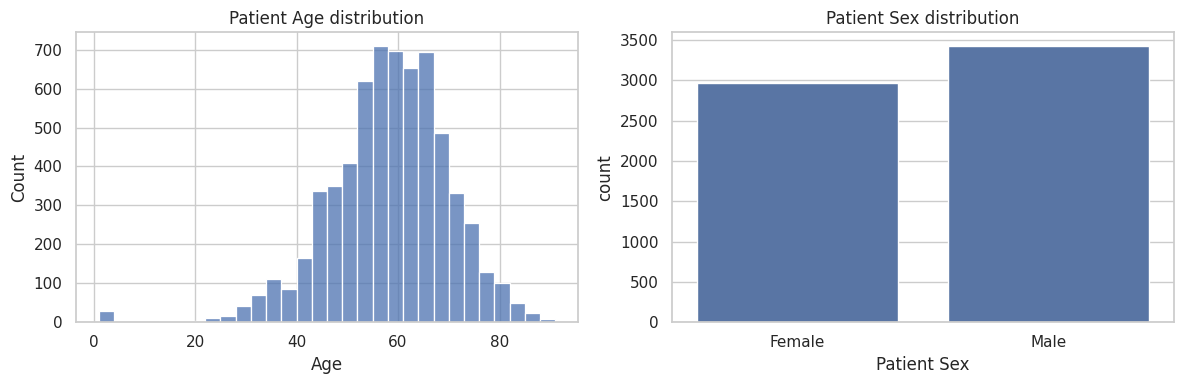

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["Patient Age"], bins=30, ax=axes[0], color="#4C72B0")
axes[0].set_title("Patient Age distribution")
axes[0].set_xlabel("Age")

sns.countplot(data=df, x="Patient Sex", ax=axes[1], color="#4C72B0")
axes[1].set_title("Patient Sex distribution")

plt.tight_layout()
plt.savefig("age_sex_distribution.png", dpi=150)
plt.show()


## 9. Class distribution chart

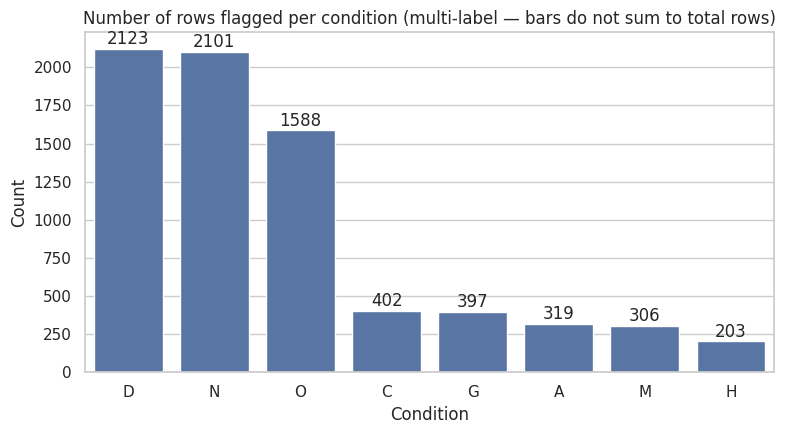

In [13]:
counts = df[disease_cols].sum().sort_values(ascending=False)

plt.figure(figsize=(8, 4.5))
sns.barplot(x=counts.index, y=counts.values, color="#4C72B0")
plt.title("Number of rows flagged per condition (multi-label — bars do not sum to total rows)")
plt.ylabel("Count")
plt.xlabel("Condition")
for i, v in enumerate(counts.values):
    plt.text(i, v + 30, str(v), ha="center")
plt.tight_layout()
plt.savefig("class_distribution.png", dpi=150)
plt.show()


## 10. Diagnostic keyword columns — a preview of the leakage risk

In [14]:
print("Sample of Left-Diagnostic Keywords values:")
print(df["Left-Diagnostic Keywords"].value_counts().head(10))


Sample of Left-Diagnostic Keywords values:
Left-Diagnostic Keywords
normal fundus                             2796
moderate non proliferative retinopathy     717
mild nonproliferative retinopathy          428
cataract                                   268
pathological myopia                        208
glaucoma                                   207
dry age-related macular degeneration       184
severe nonproliferative retinopathy        139
drusen                                     130
epiretinal membrane                        106
Name: count, dtype: int64


These free-text keyword columns essentially spell out the diagnosis (e.g. `"pathological myopia"`, `"moderate non proliferative retinopathy"`). They, along with `labels`, `target`, `filepath`, and `filename`, must be excluded from the model's input features — we'll formalize the exact feature list in the next stage (Data Cleaning / Feature Identification).

## 11. Summary of this exploration stage

Fill this in after you've run the notebook and reviewed the actual output with Claude — do not treat the bullets below as final until confirmed against your own run.

- Dataset shape: **(to confirm from your run)**
- Missing values: **(to confirm)**
- Duplicate rows: **(to confirm)**
- Unique patients vs rows: **(to confirm)** — confirms need for patient-level splitting
- Multi-label finding: **(to confirm)** % of rows have more than one condition flagged
- Myopia prevalence: **(to confirm)** % of rows — confirms Experiment 1 is imbalanced
- Leakage-risk columns identified: `Left-Diagnostic Keywords`, `Right-Diagnostic Keywords`, `labels`, `target`, `filepath`, `filename` (final list to be confirmed in the next stage)

**Next stage (not started yet):** Data Cleaning and Feature Identification — deciding the exact feature list, handling categorical encoding, and formally excluding leakage columns.
